In [1]:
import os
import hydra
from omegaconf import OmegaConf, DictConfig
from rl4co.utils.ops import unbatchify, batchify, gather_by_index

import torch
import lightning as L
from lightning.pytorch.loggers import WandbLogger
from lightning.pytorch.callbacks import ModelCheckpoint

from rl4co.utils.trainer import RL4COTrainer
from rl4co.envs import get_env

from models.zoo.icam.model import ICAM
from models.zoo.udc.model import UDC

cfg = OmegaConf.load("./configs/udc.yaml")

L.seed_everything(cfg.get("seed", 1234))

env_params = cfg.env
sub_env_params = cfg.sub_env
reviser_params_dict = OmegaConf.to_container(cfg.reviser, resolve=True)

env = get_env(**env_params)

if sub_env_params.env_name == "shpp":
    from envs.routing.shpp.env import SHPPEnv
    from models.nn.env_embeddings.init import SHPPInitEmbedding
    from models.nn.env_embeddings.context import SHPPContext
    from rl4co.models.nn.env_embeddings.dynamic import StaticEmbedding
    sub_env = SHPPEnv(**sub_env_params)
    
    reviser_params_dict['policy_kwargs'].update({
        "init_embedding": SHPPInitEmbedding(embed_dim=cfg.embed_dim),
        "context_embedding": SHPPContext(embed_dim=cfg.embed_dim),
        "dynamic_embedding": StaticEmbedding(),
    })
else:
    sub_env = get_env(**sub_env_params)

if reviser_params_dict['policy_kwargs']['pointer'] == "poly":
    from rl4co.models.nn.attention import PolyNetAttention
    reviser_params_dict['policy_kwargs']['pointer'] = PolyNetAttention(
        **cfg.poly, 
        poly_layer_dim=cfg.embed_dim*2
    )

if reviser_params_dict['policy_kwargs']['encoder'] == "am":
    from rl4co.models.zoo.am.encoder import AttentionModelEncoder
    reviser_params_dict['policy_kwargs']['encoder'] = AttentionModelEncoder(
        embed_dim=cfg.embed_dim,
        num_heads=cfg.num_heads,
        num_layers=reviser_params_dict['policy_kwargs']['num_encoder_layers'],
        normalization=reviser_params_dict['policy_kwargs']['normalization'],
    )

reviser = ICAM(
    env=sub_env,
    **reviser_params_dict,
)

model_params = cfg.model
model = UDC(
    env=env,
    reviser=reviser,
    **model_params,
)

if cfg.ckpt_path:
    ckpt_state_dict = torch.load(cfg.ckpt_path)['state_dict']
    model.load_state_dict(ckpt_state_dict)

/home/cpz/anaconda3/envs/rl4co/lib/python3.12/site-packages/torchrl/data/replay_buffers/samplers.py:37: UserWarning: Failed to import torchrl C++ binaries. Some modules (eg, prioritized replay buffers) may not work with your installation. If you installed TorchRL from PyPI, please report the bug on TorchRL github. If you installed TorchRL locally and/or in development mode, check that you have all the required compiling packages.
  warnings.warn(EXTENSION_WARNING)
/home/cpz/anaconda3/envs/rl4co/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/cpz/anaconda3/envs/rl4co/lib/python3.12/site-packages/torch/jit/frontend.py:1209: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  elif isinstance(value, ast.Str):
/home/cpz/anaconda3/envs/rl4co/lib/pytho

Problem 1 | Cost: 18.339
Problem 2 | Cost: 18.072
Problem 3 | Cost: 17.444


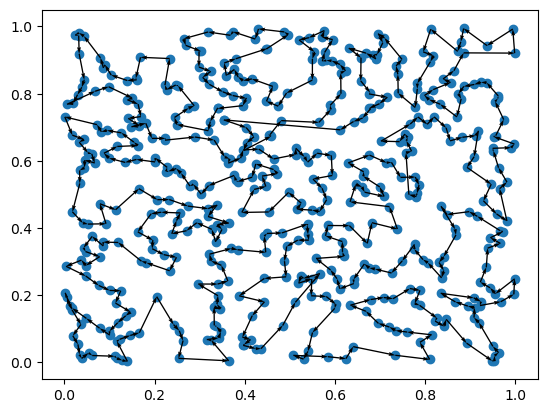

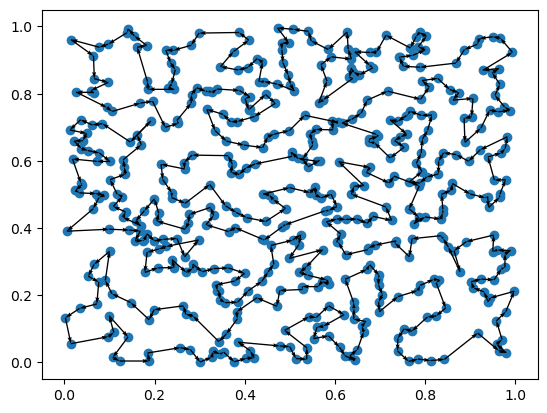

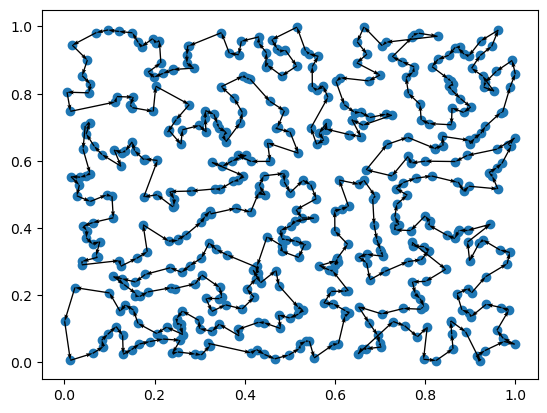

In [3]:
device = "cpu"
n_instances = 3
num_starts = cfg.model.num_starts
td_init = env.reset(batch_size=[n_instances]).to(device)
model = model.to(device)

out = model(td_init.clone(), 
            phase="test", 
            num_starts=num_starts,
            decode_type="multistart_sampling",
            multisample=True, 
            return_actions=True
            )
actions = out['actions'].cpu().detach()
rewards = out['reward'].cpu().detach()
if num_starts > 1:
    actions = unbatchify(actions, num_starts)
    rewards = unbatchify(rewards, num_starts)
    max_rewards, max_idxs = rewards.max(dim=1)
    best_actions = gather_by_index(actions, max_idxs, dim=1)
else:
    max_rewards = rewards
    best_actions = actions

for i in range(3):
    print(f"Problem {i+1} | Cost: {-max_rewards[i]:.3f}")
    env.render(td_init[i], best_actions[i])

Problem 1 | Improved Cost: 17.540
Problem 2 | Improved Cost: 17.640
Problem 3 | Improved Cost: 16.875


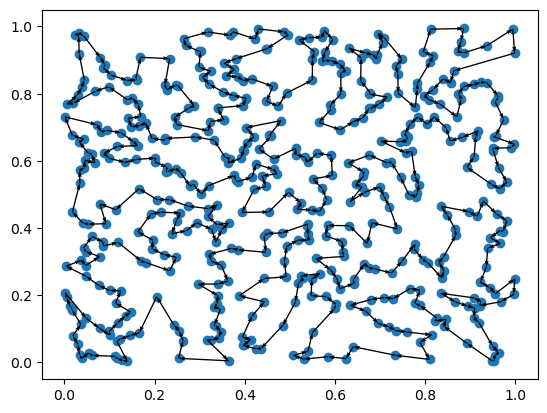

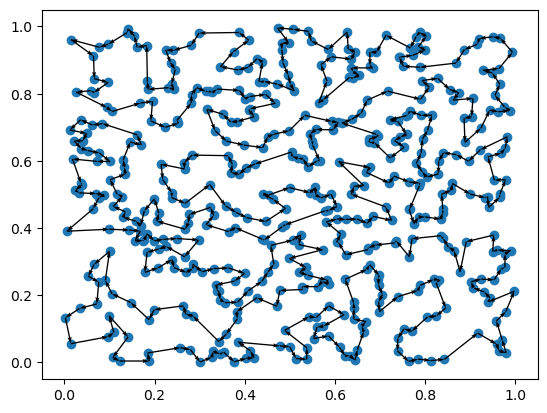

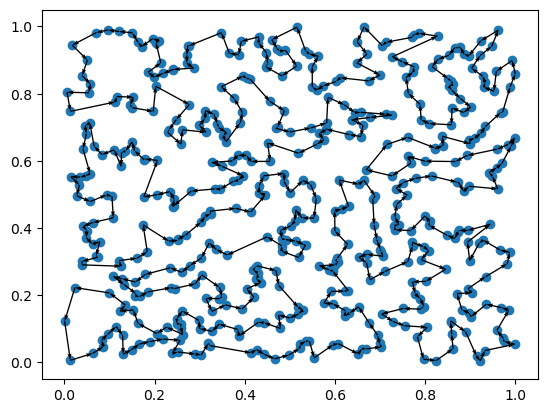

In [5]:
improved_actions = env.local_search(td_init, best_actions)
improved_rewards = env.get_reward(td_init, improved_actions)

for i in range(3):
    print(f"Problem {i+1} | Improved Cost: {-improved_rewards[i]:.3f}")
    env.render(td_init[i], improved_actions[i])